# Tugas Praktikum

Import library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Muat dataset dan memisahkan fitur dari label

In [2]:
df = pd.read_csv("Iris.csv")

feature_columns = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm",
]

X = df[feature_columns].to_numpy()
species = df["Species"].to_numpy()

display(df.head())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Standardisasi Fitur

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Menjalankan HDBSCAN dan menghitung hasilnya

In [4]:
model = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5,
    metric="euclidean",
)

labels = model.fit_predict(X_scaled)

n_clusters = len(set(labels) - {-1})
n_noise = np.sum(labels == -1)

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)
print(f"Persentase noise: {n_noise / len(labels) * 100:.2f}%")

display(
    pd.Series(labels, name="Cluster")
    .value_counts()
    .sort_index()
    .rename("Jumlah anggota")
    .to_frame()
)

Jumlah cluster: 2
Jumlah noise: 2
Persentase noise: 1.33%


,Jumlah anggota
Cluster,
-1,2
0,99
1,49


Visualisasi dengan PCA

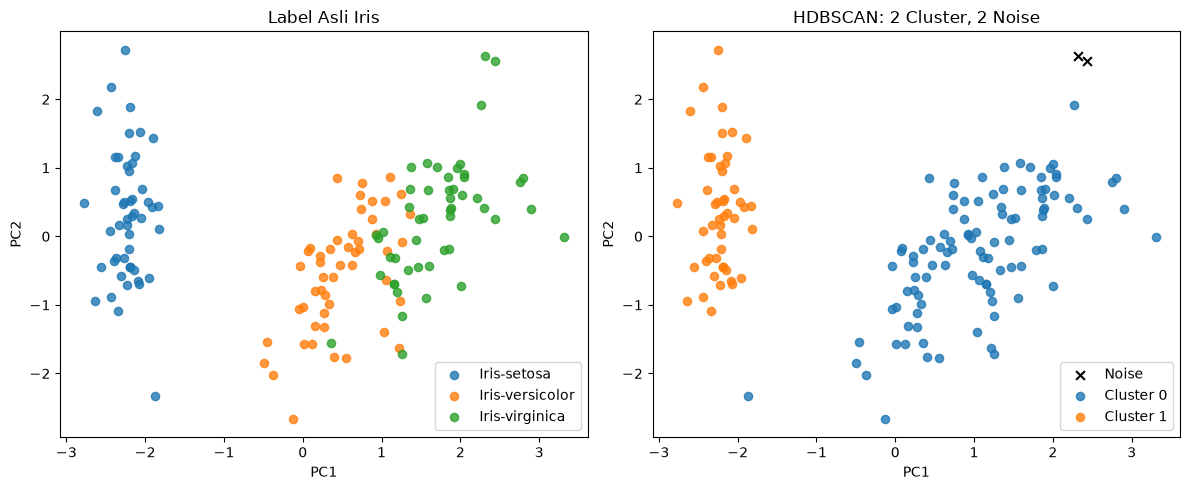

Variansi yang dijelaskan oleh dua komponen PCA: 95.80%


In [5]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Grafik label asli
for name in np.unique(species):
    mask = species == name
    axes[0].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        label=name, s=35, alpha=0.8
    )

axes[0].set_title("Label Asli Iris")


for label in np.unique(labels):
    mask = labels == label

    if label == -1:
        axes[1].scatter(
            X_pca[mask, 0], X_pca[mask, 1],
            color="black", marker="x", label="Noise", s=40
        )
    else:
        axes[1].scatter(
            X_pca[mask, 0], X_pca[mask, 1],
            label=f"Cluster {label}", s=35, alpha=0.8
        )

axes[1].set_title(
    f"HDBSCAN: {n_clusters} Cluster, {n_noise} Noise"
)

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend()

plt.tight_layout()
plt.show()

print(
    "Variansi yang dijelaskan oleh dua komponen PCA:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

Membandingkan cluster dengan label asli

In [6]:
comparison = pd.crosstab(
    pd.Series(species, name="Spesies asli"),
    pd.Series(labels, name="Cluster"),
)

display(comparison)

Cluster,-1,0,1
Spesies asli,,,
Iris-setosa,0,1,49
Iris-versicolor,0,50,0
Iris-virginica,2,48,0


Analisis Berdasarkan Output Kode Program

Berdasarkan output notebook, HDBSCAN dengan min_cluster_size=5 dan min_samples=5 menghasilkan 2 klaster dan 2 noise (1,33%) dari 150 data.

Hasil clustering sesuai sebagian dengan label asli. Cluster 1 berhasil mengelompokkan 49 dari 50 data setosa secara terpisah. Namun, Cluster 0 menggabungkan seluruh versicolor, 48 virginica, dan satu setosa. Artinya, pada pengaturan ini HDBSCAN belum memisahkan versicolor dan virginica menjadi kelompok tersendiri.

Penggabungan tersebut menunjukkan bahwa struktur kepadatan fitur yang ditemukan algoritma tidak sepenuhnya mengikuti tiga label spesies. Dua data virginica ditetapkan sebagai noise karena tidak memenuhi kriteria keanggotaan klaster pada pengaturan yang digunakan; hal ini tidak otomatis berarti datanya salah.

PCA mempertahankan 95,80% variansi data dalam dua komponen, sehingga visualisasinya mewakili sebagian besar variasi fitur.